In [1]:
# Environment and path setup is handled in the next cell.


Mounted at /content/drive


In [2]:
import math
import numpy as np
import sys
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Files available: {os.listdir(utils_path)}")

Arquivos disponíveis em utils: ['utility_reset.py', 'filtered_paths.py', '__pycache__', 'intersection_utils.py', 'point_generator.py', 'path_analysis.py', 'nextSteps.txt', 'test_paths_in_subregions.ipynb', 'testing_data_structures.ipynb', 'testing_points_in_subregions.ipynb', 'PiaNo.ipynb', 'testing_paths.ipynb', 'path_pairs_of_lines vs  path_pairs_of_edges.txt', 'node_edge_mapping_analysis.ipynb', 'region_checks.py', 'plotting_old.py', 'plotting.py', 'test_simple_percolation.ipynb', 'node_edge_visualization_with_ids.ipynb', 'pruning.py', 'test_pruning_with_dangling_bonds.ipynb']


In [3]:
import matplotlib.pyplot as plt
from point_generator import *
from region_checks import *
from intersection_utils import *
from path_analysis import *
from plotting import *
from pruning import *
from filtered_paths import *
from utility_reset import *

## Running the experiment

The `PiaNo.ipynb` pipeline (N = 30, a = 0.70): sticks, intersections, source and drain nodes, `find_path` and the standard plots. The stored outputs predate the switch of `generate_points` to the `clip` boundary rule, so a re-run draws a different network.

In [91]:
# Variáveis principais
a = 0.75
N = 20  # Reduced from 30 to 20 for clearer visualization

points_1 = []
points_2 = []
angles = []
graph = [] #arestas
nodes = []
intersected_line_1 = []
intersected_line_2 = []
intersections_points = []
all_connected_nodes = []
solutions = []
A = []
L = []
paths = []

In [92]:
generate_points(N, points_1, points_2, angles, a)

In [93]:
intersections_points, intersected_line_1, intersected_line_2, graph = identify_intersections(points_1, points_2, intersections_points, intersected_line_1, intersected_line_2, graph, angles, a, N)

In [94]:
len(intersections_points)

44

In [95]:
boundary_condition_source = []
boundary_condition_drain = []

In [96]:
for i in range(len(intersections_points)):
  if intersections_points[i][0] < 0.1:
    boundary_condition_source.append(i)
  elif intersections_points[i][0] > 0.9:
    boundary_condition_drain.append(i)

In [97]:
print("Number of identified intersection points =", len(intersections_points))
print("In the source contact region =", len(boundary_condition_source))
print("In the drain contact region =", len(boundary_condition_drain))
print(boundary_condition_source)

Number of identified intersection points = 44
In the source contact region = 1
In the drain contact region = 1
[33]


In [98]:
path_nodes, path_pairs_of_lines, path_pairs_of_edges, all_path_perc = [], [], [], []

In [99]:
for i in boundary_condition_source:
  do_not_check = 0
  number_path = len(all_connected_nodes)
  for k in range(0,number_path):
    if i in all_connected_nodes[k]:
      do_not_check = 1
  if do_not_check == 0:
    print(f"Path number = {number_path}")
    print(f"node = {i}")
    start_node = i
    nodes, pair_of_lines, pair_of_edges, path_perc = find_path(intersections_points, graph, start_node)
    path_nodes.append(nodes)
    path_pairs_of_lines.append(pair_of_lines)
    path_pairs_of_edges.append(pair_of_edges,)
    all_path_perc.append(path_perc)
  # print(f"All nodes = {all_connected_nodes}")
  # print(f"All lines = {pair_of_lines}")

Path number = 0
node = 33
valor de queue antes = deque([33])
valor de queue depois = deque([])
nós visitados {33}
valor de target edge = (16, 3)
valor de path_pairs_of_lines = [(16, 3)]
valor do i = 13
valor do current node = 33
valor da queue após append = deque([13])
valor do path_pairs_of_nodes[33, 13]
valor do path_pairs_of_lines = [(16, 3), (8, 16)]
valor do path_pairs_of_edges = [(33, 13)]
valor de queue antes = deque([13])
valor de queue depois = deque([])
nós visitados {33, 13}
valor de target edge = (8, 16)
valor do i = 5
valor do current node = 13
valor da queue após append = deque([5])
valor do path_pairs_of_nodes[33, 13, 5]
valor do path_pairs_of_lines = [(16, 3), (8, 16), (8, 0)]
valor do path_pairs_of_edges = [(33, 13), (13, 5)]
valor do i = 6
valor do current node = 13
valor da queue após append = deque([5, 6])
valor do path_pairs_of_nodes[33, 13, 5, 6]
valor do path_pairs_of_lines = [(16, 3), (8, 16), (8, 0), (8, 1)]
valor do path_pairs_of_edges = [(33, 13), (13, 5), (1

In [100]:
print(path_nodes) #create list of the correspoding pairs of edges
print(path_pairs_of_lines) #check what it is
print(path_pairs_of_edges) #create list of the correspoding nodes
print(all_path_perc)

[[33, 13, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 35, 0, 2, 18, 22, 26, 34, 41, 27, 23, 3, 19, 20, 24, 28, 42, 21, 29, 36, 25, 30, 37, 31, 38, 32, 40, 43, 4, 39]]
[[(16, 3), (8, 16), (8, 0), (8, 1), (8, 2), (8, 7), (8, 11), (8, 12), (8, 13), (8, 14), (8, 17), (8, 19), (18, 8), (2, 0), (5, 0), (11, 0), (13, 0), (14, 0), (18, 0), (19, 0), (14, 1), (13, 2), (5, 11), (11, 17), (12, 11), (13, 11), (14, 11), (19, 11), (12, 17), (14, 12), (18, 12), (13, 19), (14, 13), (18, 13), (14, 19), (18, 14), (15, 17), (18, 17), (19, 17), (5, 19), (18, 15)]]
[[(33, 13), (13, 5), (13, 6), (13, 7), (13, 8), (13, 9), (13, 10), (13, 11), (13, 12), (13, 14), (13, 15), (13, 35), (5, 0), (5, 2), (5, 18), (5, 22), (5, 26), (5, 34), (5, 41), (6, 27), (7, 23), (9, 3), (9, 19), (9, 20), (9, 24), (9, 28), (9, 42), (10, 21), (10, 29), (10, 36), (11, 25), (11, 30), (11, 37), (12, 31), (12, 38), (14, 32), (14, 40), (14, 43), (15, 4), (35, 39)]]
[1]


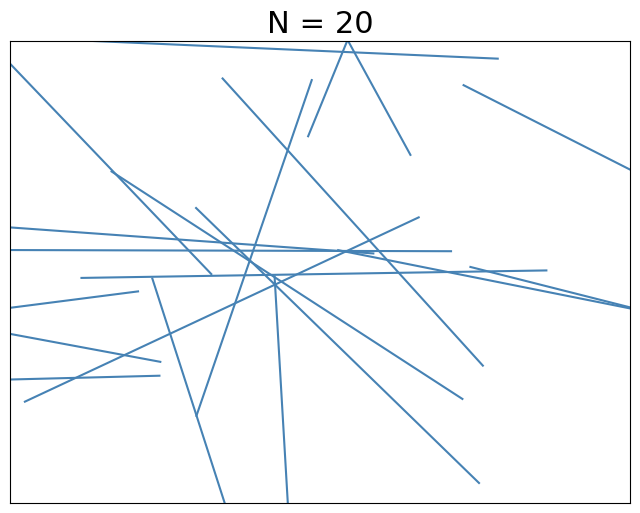

In [101]:
plot_lines(N, points_1, points_2)

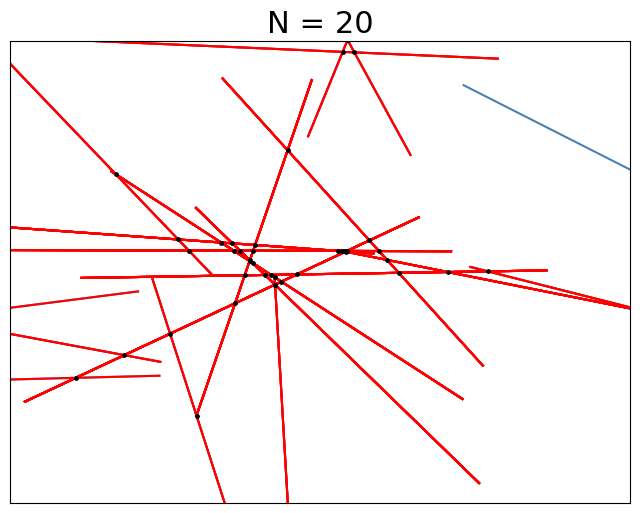

In [102]:
plot_lines_intersection(N, points_1, points_2, intersected_line_1, intersected_line_2, intersections_points)

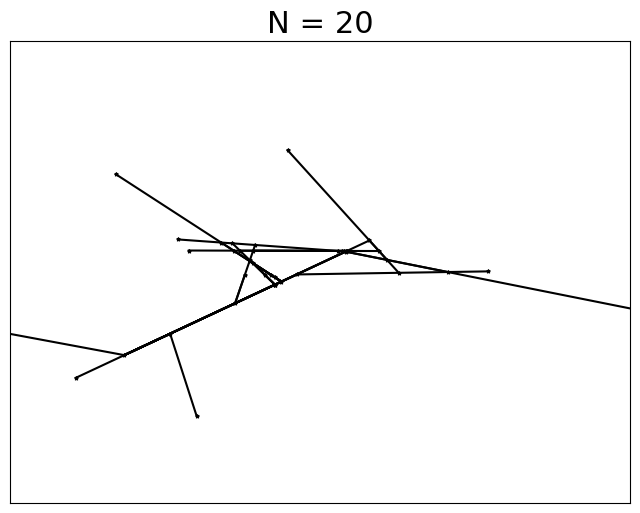

In [103]:
plot_only_paths(N, intersections_points, path_nodes, path_pairs_of_edges)

1


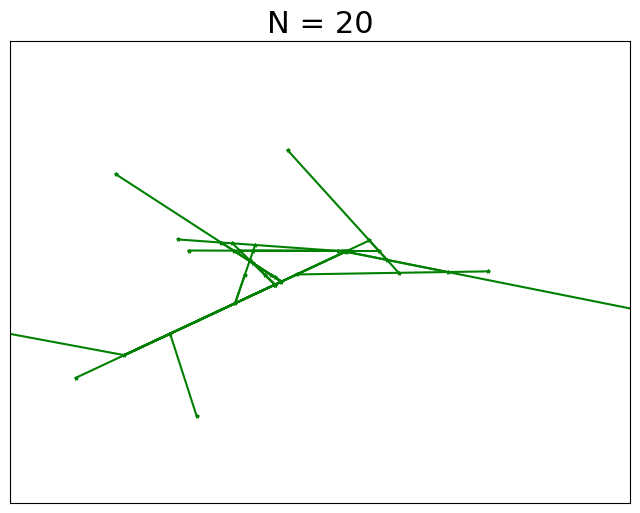

In [104]:
plot_percolating_paths(N, intersections_points, path_nodes, path_pairs_of_edges, all_path_perc)

## Creating the four data structures

Node-to-edge and edge-to-node mappings, plus integer IDs for nodes and edges, used to label the plots below. The mapping functions are the same as in `node_edge_mapping_analysis.ipynb`.

In [105]:
def create_node_to_edges_mapping(path_nodes, path_pairs_of_edges):
    """
    Data Structure 1: Node → Edge Pairs
    Given a node, returns all edge pairs that include this node.
    """
    node_to_edges = {}

    for path_idx in range(len(path_pairs_of_edges)):
        edges = path_pairs_of_edges[path_idx]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair

                if node1 not in node_to_edges:
                    node_to_edges[node1] = []
                if edge_pair not in node_to_edges[node1]:
                    node_to_edges[node1].append(edge_pair)

                if node2 not in node_to_edges:
                    node_to_edges[node2] = []
                if edge_pair not in node_to_edges[node2]:
                    node_to_edges[node2].append(edge_pair)

    return node_to_edges

def create_edge_to_nodes_mapping(path_pairs_of_edges):
    """
    Data Structure 2: Edge Pair → Nodes
    Given an edge pair, returns the two nodes it connects.
    """
    edge_to_nodes = {}

    for path_idx in range(len(path_pairs_of_edges)):
        edges = path_pairs_of_edges[path_idx]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                if edge_pair not in edge_to_nodes:
                    edge_to_nodes[edge_pair] = (edge_pair[0], edge_pair[1])

    return edge_to_nodes

def create_edge_id_mapping(path_pairs_of_edges):
    """
    Data Structure 3: Edge → Edge ID
    Assigns a unique ID to each edge pair.
    """
    edge_to_id = {}
    edge_id_counter = 0

    for path_idx in range(len(path_pairs_of_edges)):
        edges = path_pairs_of_edges[path_idx]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                if edge_pair not in edge_to_id:
                    edge_to_id[edge_pair] = edge_id_counter
                    edge_id_counter += 1

    return edge_to_id

def create_node_id_mapping(path_nodes):
    """
    Data Structure 4: Node → Simplified display tracking
    Maps node indices to their participation info.
    """
    node_info = {}

    for path_idx, nodes in enumerate(path_nodes):
        for node in nodes:
            if node not in node_info:
                node_info[node] = {
                    'id': node,
                    'paths': []
                }
            node_info[node]['paths'].append(path_idx)

    return node_info

In [106]:
# Create all four data structures
node_to_edges = create_node_to_edges_mapping(path_nodes, path_pairs_of_edges)
edge_to_nodes = create_edge_to_nodes_mapping(path_pairs_of_edges)
edge_to_id = create_edge_id_mapping(path_pairs_of_edges)
node_info = create_node_id_mapping(path_nodes)

# Create reverse mapping for edge IDs
id_to_edge = {v: k for k, v in edge_to_id.items()}

print("Data structures created successfully!")
print(f"Total nodes: {len(node_to_edges)}")
print(f"Total edges: {len(edge_to_nodes)}")
print(f"Edge IDs assigned: {len(edge_to_id)}")

Data structures created successfully!
Total nodes: 41
Total edges: 40
Edge IDs assigned: 40


## Visualization V1: edge-centric view

Each edge is labelled with its ID, and node IDs appear at its endpoints.

In [107]:
def plot_edge_centric_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                           edge_to_id, edge_to_nodes, node_to_edges,
                           show_all_nodes=True, path_filter=None):
    """
    Visualization V1: Edge-Centric View

    Emphasizes edges by showing:
    - Edge IDs as labels on the edges (midpoint)
    - Node IDs at the endpoints
    - Unique color for each edge using graph coloring to avoid same colors for connected edges
    """
    # Build edge adjacency graph - two edges are adjacent if they share a node
    edge_adjacency = {edge_pair: set() for edge_pair in edge_to_id.keys()}
    for node, connected_edges in node_to_edges.items():
        for i, edge1 in enumerate(connected_edges):
            for edge2 in connected_edges[i+1:]:
                edge_adjacency[edge1].add(edge2)
                edge_adjacency[edge2].add(edge1)

    # Graph coloring algorithm - assign colors ensuring adjacent edges get different colors
    edge_colors_assigned = {}
    color_palette = plt.cm.hsv(np.linspace(0, 0.95, min(len(edge_to_id), 20)))

    for edge_pair in sorted(edge_to_id.keys(), key=lambda e: len(edge_adjacency[e]), reverse=True):
        # Find which colors are used by adjacent edges
        used_colors = set()
        for adj_edge in edge_adjacency[edge_pair]:
            if adj_edge in edge_colors_assigned:
                used_colors.add(edge_colors_assigned[adj_edge])

        # Assign the first available color
        for color_idx in range(len(color_palette)):
            if color_idx not in used_colors:
                edge_colors_assigned[edge_pair] = color_idx
                break
        else:
            # If we run out of colors, use a distinct one from extended palette
            edge_colors_assigned[edge_pair] = len(used_colors)

    # Create color dictionary with actual colors
    max_color_idx = max(edge_colors_assigned.values()) + 1
    full_palette = plt.cm.hsv(np.linspace(0, 0.95, max_color_idx))
    edge_color_dict = {edge_pair: full_palette[color_idx]
                       for edge_pair, color_idx in edge_colors_assigned.items()}

    fig, ax = plt.subplots(figsize=(24, 20))  # Much larger window

    x_values, y_values = zip(*intersections_points)

    # Determine which paths to show
    paths_to_show = range(len(path_nodes)) if path_filter is None else path_filter

    # Track which edges have been drawn to avoid duplicates
    drawn_edges = set()

    # Calculate node degrees for positioning adjustments
    node_degrees = {}
    for node in range(len(intersections_points)):
        if node in node_to_edges:
            node_degrees[node] = len(node_to_edges[node])
        else:
            node_degrees[node] = 0

    # Create adjusted node positions to handle overlaps
    adjusted_x = {}
    adjusted_y = {}
    for node in range(len(intersections_points)):
        adjusted_x[node] = x_values[node]
        adjusted_y[node] = y_values[node]

    # Apply small offset to overlapping nodes
    for i, node_i in enumerate(range(len(intersections_points))):
        for node_j in range(i + 1, len(intersections_points)):
            dist = ((x_values[node_i] - x_values[node_j])**2 +
                   (y_values[node_i] - y_values[node_j])**2)**0.5
            if dist < 0.02:  # Nodes are too close
                # Push them apart slightly
                angle = node_i * 0.5  # Different angle for each node
                adjusted_x[node_i] += 0.012 * math.cos(angle)
                adjusted_y[node_i] += 0.012 * math.sin(angle)
                adjusted_x[node_j] -= 0.012 * math.cos(angle)
                adjusted_y[node_j] -= 0.012 * math.sin(angle)

    # Plot each path
    for path_idx in paths_to_show:
        if path_idx >= len(path_nodes):
            continue

        edges = path_pairs_of_edges[path_idx]

        # Plot edges with IDs
        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair

                # Skip if this edge was already drawn
                if edge_pair in drawn_edges:
                    continue
                drawn_edges.add(edge_pair)

                edge_id = edge_to_id[edge_pair]

                # Get unique color for this edge
                edge_color = edge_color_dict[edge_pair]

                # Draw a thick white outline for the edge first (creates contrast)
                ax.plot([adjusted_x[node1], adjusted_x[node2]],
                       [adjusted_y[node1], adjusted_y[node2]],
                       color='white', linewidth=7, alpha=0.9, zorder=0)

                # Draw the edge using adjusted positions with its unique color
                ax.plot([adjusted_x[node1], adjusted_x[node2]],
                       [adjusted_y[node1], adjusted_y[node2]],
                       color=edge_color, linewidth=5, alpha=1.0, zorder=1)

                # Calculate edge midpoint and direction
                mid_x_edge = (adjusted_x[node1] + adjusted_x[node2]) / 2
                mid_y_edge = (adjusted_y[node1] + adjusted_y[node2]) / 2

                dx = adjusted_x[node2] - adjusted_x[node1]
                dy = adjusted_y[node2] - adjusted_y[node1]
                edge_length = (dx**2 + dy**2)**0.5

                if edge_length > 0:
                    # Perpendicular vector (rotated 90 degrees)
                    perp_x = -dy / edge_length
                    perp_y = dx / edge_length

                    # Use hash-based offset for better distribution and less overlap
                    # Combine edge coordinates to create unique offset pattern
                    hash_val = hash((node1, node2, edge_id))
                    offset_level = (hash_val % 7) - 3  # -3, -2, -1, 0, 1, 2, 3
                    perp_offset = 0.055 * offset_level  # ±0.165, ±0.11, ±0.055, 0

                    # Vary position along edge too, not just perpendicular
                    along_offset = 0.5 + ((hash_val // 7) % 5 - 2) * 0.08  # 0.34 to 0.66

                    # Position label with both perpendicular and along-edge variation
                    label_x = adjusted_x[node1] + along_offset * (adjusted_x[node2] - adjusted_x[node1])
                    label_y = adjusted_y[node1] + along_offset * (adjusted_y[node2] - adjusted_y[node1])
                    label_x += perp_x * perp_offset
                    label_y += perp_y * perp_offset

                    # Draw a VERY visible thick arrow/line from edge to label in matching color
                    ax.annotate('', xy=(label_x, label_y), xytext=(mid_x_edge, mid_y_edge),
                               arrowprops=dict(arrowstyle='->', color=edge_color,
                                             lw=3, alpha=0.9), zorder=2)

                    # Add edge ID label with matching colored background
                    ax.text(label_x, label_y, f'E{edge_id}',
                           fontsize=12, fontweight='bold', color='black',
                           bbox=dict(boxstyle='round,pad=0.4', facecolor=edge_color,
                                    edgecolor='black', alpha=1.0, linewidth=3),
                           ha='center', va='center', zorder=3)

    # Plot nodes with adjusted positions
    nodes_to_show = set()
    for path_idx in paths_to_show:
        if path_idx < len(path_nodes):
            nodes_to_show.update(path_nodes[path_idx])

    for node in nodes_to_show:
        # Draw node with white fill and black border
        ax.scatter(adjusted_x[node], adjusted_y[node],
                  s=550, c='white', edgecolors='black',
                  linewidths=3.5, zorder=4, marker='o')

        # Add node ID label
        ax.text(adjusted_x[node], adjusted_y[node], f'{node}',
               fontsize=14, fontweight='bold', color='black',
               ha='center', va='center', zorder=5)

    # Add title and formatting
    ax.set_title('V1: Edge-Centric View\nEach Edge Has Unique Color Matching Its Label',
                fontsize=22, fontweight='bold', pad=30)

    # Set dynamic axis limits based on actual data with margin
    x_min, x_max = min(x_values), max(x_values)
    y_min, y_max = min(y_values), max(y_values)
    x_margin = (x_max - x_min) * 0.1 if x_max > x_min else 0.1
    y_margin = (y_max - y_min) * 0.1 if y_max > y_min else 0.1
    ax.set_xlim(x_min - x_margin, x_max + x_margin)
    ax.set_ylim(y_min - y_margin, y_max + y_margin)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.4, linestyle='--', linewidth=1.5)

    plt.tight_layout()
    plt.savefig('V1_Edge_Centric_View.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print edge information
    print("\n" + "="*70)
    print("V1: EDGE-CENTRIC VIEW - Edge Information")
    print("="*70)
    for edge_pair, edge_id in sorted(edge_to_id.items(), key=lambda x: x[1]):
        node1, node2 = edge_pair
        print(f"Edge E{edge_id}: connects Node {node1} ← → Node {node2}")

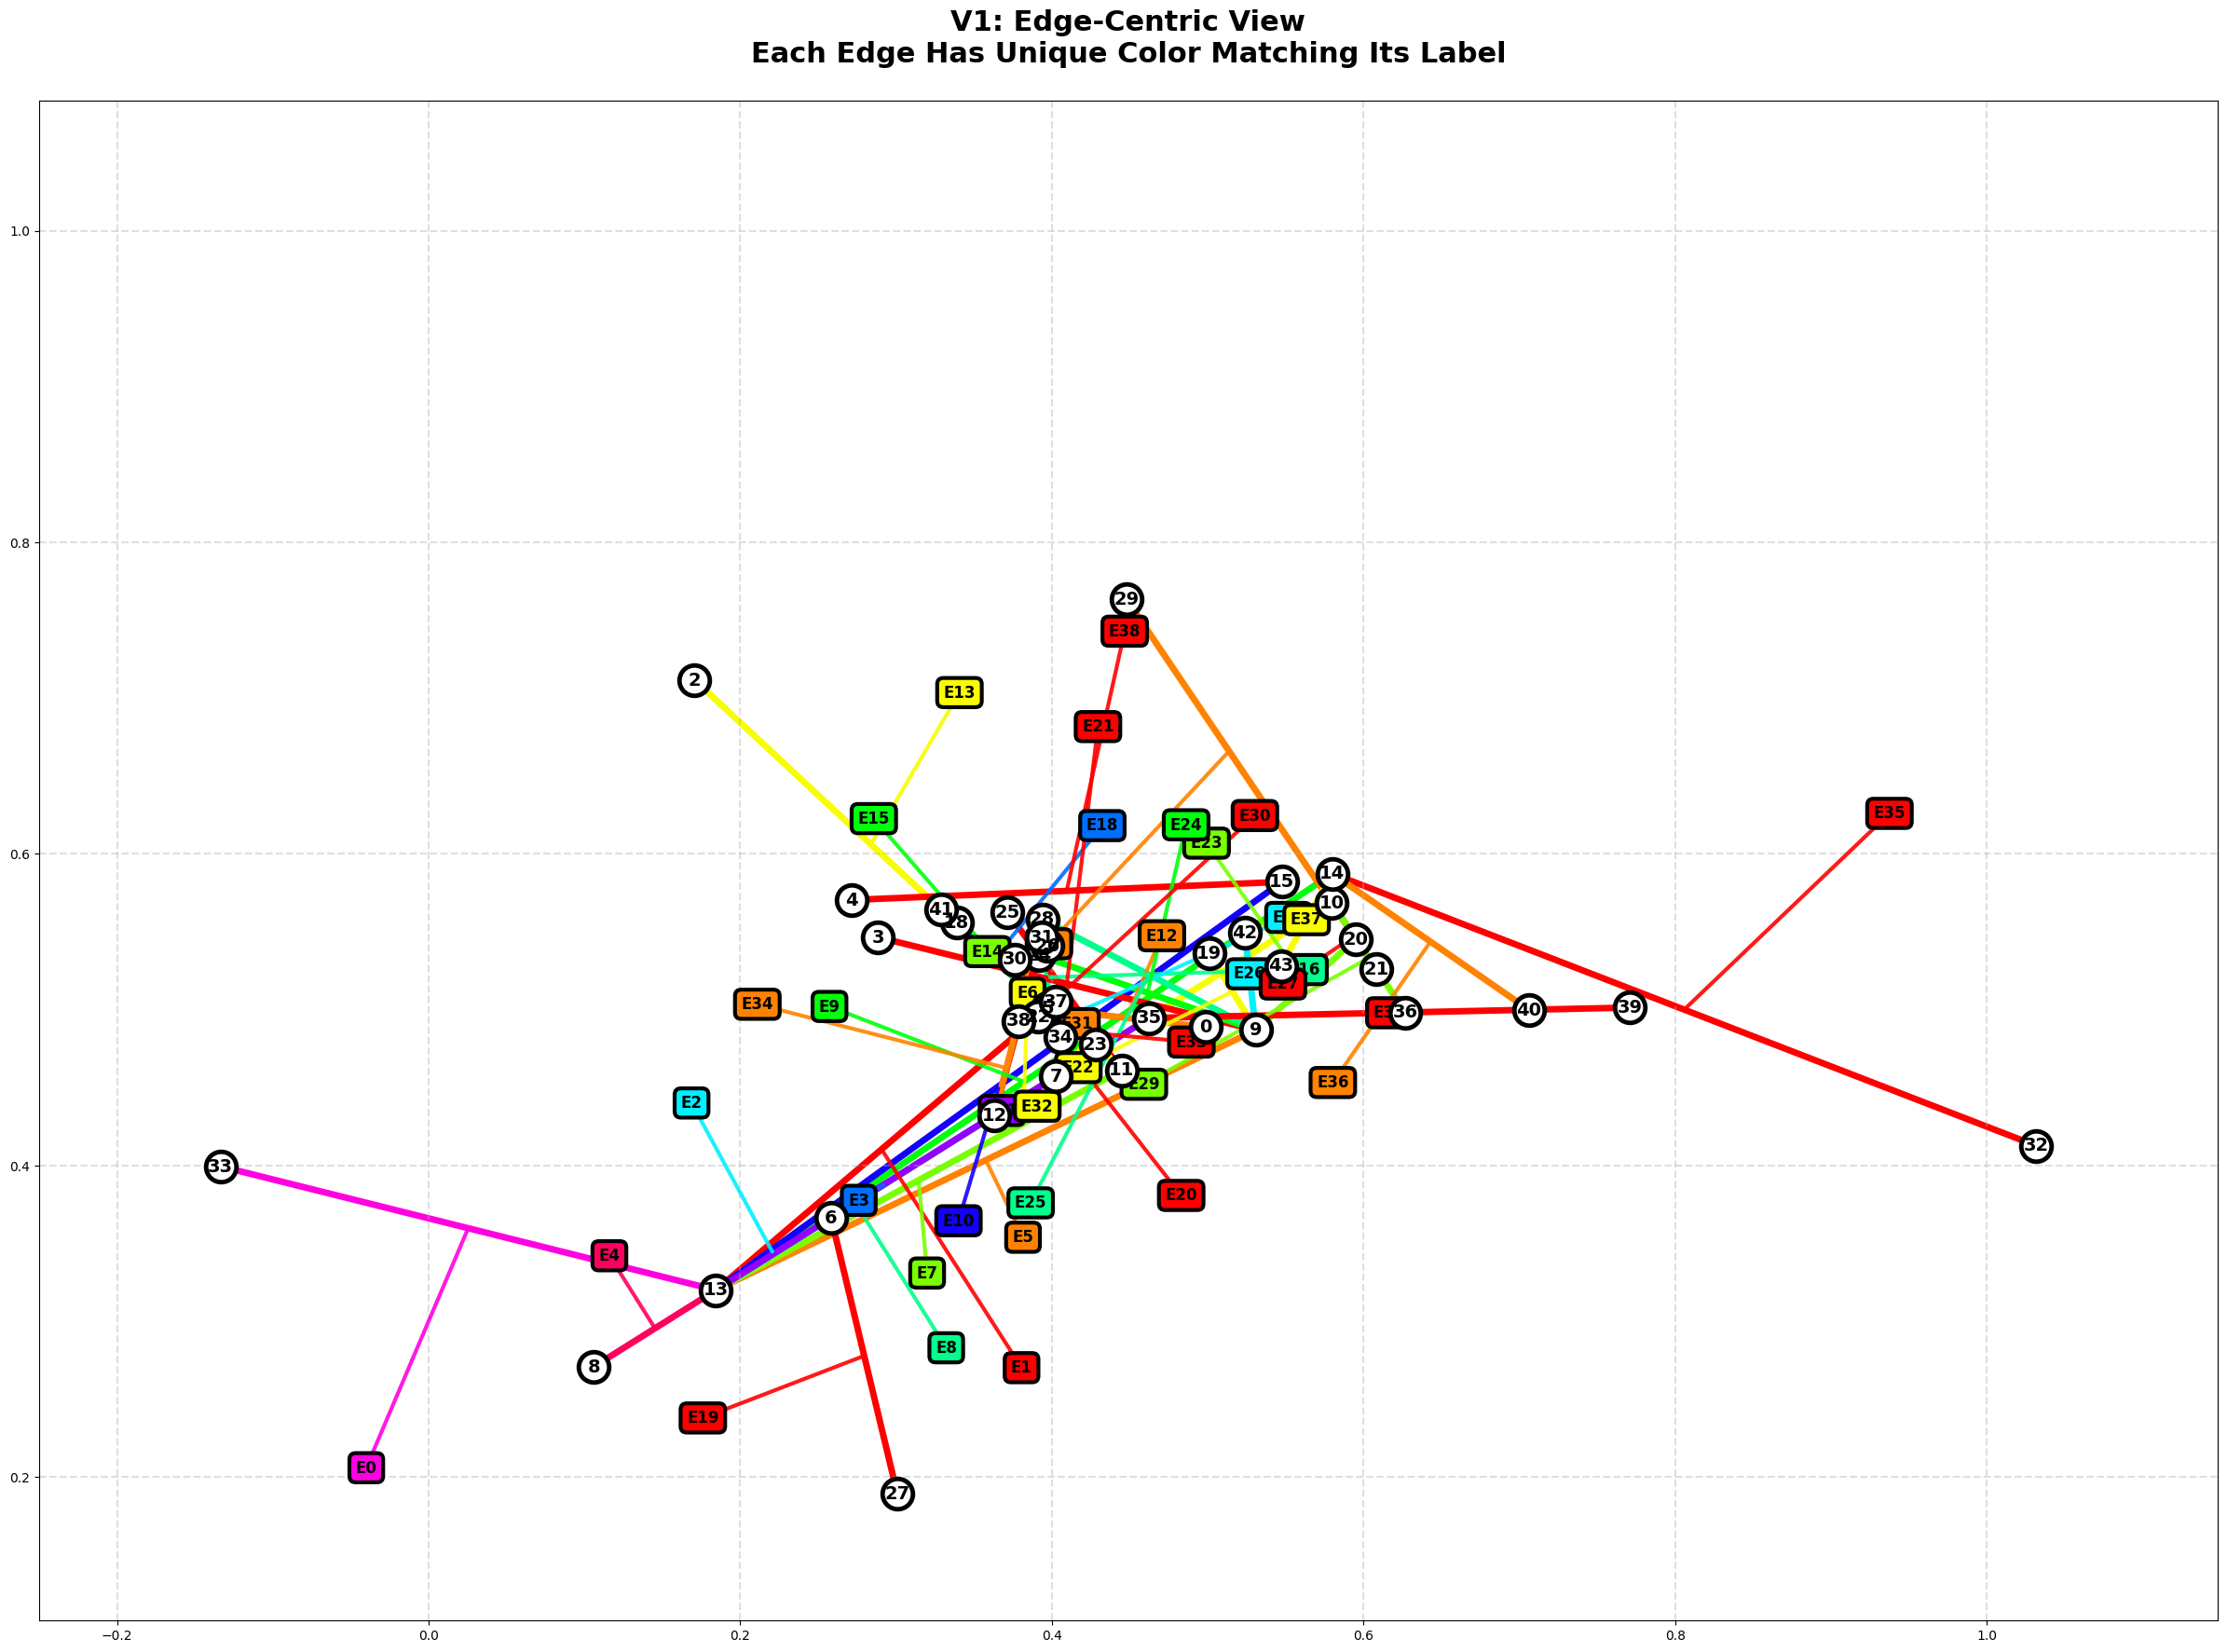


V1: EDGE-CENTRIC VIEW - Edge Information
Edge E0: connects Node 33 ← → Node 13
Edge E1: connects Node 13 ← → Node 5
Edge E2: connects Node 13 ← → Node 6
Edge E3: connects Node 13 ← → Node 7
Edge E4: connects Node 13 ← → Node 8
Edge E5: connects Node 13 ← → Node 9
Edge E6: connects Node 13 ← → Node 10
Edge E7: connects Node 13 ← → Node 11
Edge E8: connects Node 13 ← → Node 12
Edge E9: connects Node 13 ← → Node 14
Edge E10: connects Node 13 ← → Node 15
Edge E11: connects Node 13 ← → Node 35
Edge E12: connects Node 5 ← → Node 0
Edge E13: connects Node 5 ← → Node 2
Edge E14: connects Node 5 ← → Node 18
Edge E15: connects Node 5 ← → Node 22
Edge E16: connects Node 5 ← → Node 26
Edge E17: connects Node 5 ← → Node 34
Edge E18: connects Node 5 ← → Node 41
Edge E19: connects Node 6 ← → Node 27
Edge E20: connects Node 7 ← → Node 23
Edge E21: connects Node 9 ← → Node 3
Edge E22: connects Node 9 ← → Node 19
Edge E23: connects Node 9 ← → Node 20
Edge E24: connects Node 9 ← → Node 24
Edge E25: conn

In [108]:
# Generate V1 visualization
plot_edge_centric_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                       edge_to_id, edge_to_nodes, node_to_edges)

## Visualization V2: node-centric view

Each node is labelled with its ID, with the IDs of its edges nearby.

In [109]:
def plot_node_centric_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                          edge_to_id, edge_to_nodes, node_to_edges,
                          show_edge_ids_near_nodes=True, path_filter=None):
    """
    Visualization V2: Node-Centric View

    Emphasizes nodes by showing:
    - Large node markers with IDs
    - Edge IDs near the nodes they connect (offset from midpoint)
    - Node degree (number of connections) as node size
    """
    # Color palette
    colors = plt.cm.tab10(range(10))
    if len(path_nodes) > 10:
        colors = plt.cm.tab20(range(20))

    fig, ax = plt.subplots(figsize=(24, 20))  # Much larger window

    x_values, y_values = zip(*intersections_points)

    # Determine which paths to show
    paths_to_show = range(len(path_nodes)) if path_filter is None else path_filter

    # Plot edges first (background)
    for path_idx in paths_to_show:
        if path_idx >= len(path_nodes):
            continue

        edges = path_pairs_of_edges[path_idx]
        color = colors[path_idx % len(colors)]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair

                # Draw the edge - thicker for better visibility
                ax.plot([x_values[node1], x_values[node2]],
                       [y_values[node1], y_values[node2]],
                       color=color, linewidth=4, alpha=0.6, zorder=1)

    # Calculate node degrees
    node_degrees = {node: len(edges) for node, edges in node_to_edges.items()}

    # Plot nodes with emphasis
    nodes_to_show = set()
    for path_idx in paths_to_show:
        if path_idx < len(path_nodes):
            nodes_to_show.update(path_nodes[path_idx])

    for node in nodes_to_show:
        degree = node_degrees.get(node, 1)
        node_size = 600 + degree * 100  # Larger base size, scales with degree

        # Draw node with size based on degree
        ax.scatter(x_values[node], y_values[node],
                  s=node_size, c='lightblue', edgecolors='darkblue',
                  linewidths=4, zorder=4, marker='o', alpha=0.9)

        # Add node ID label - larger text
        ax.text(x_values[node], y_values[node], f'N{node}',
               fontsize=15, fontweight='bold', color='darkblue',
               ha='center', va='center', zorder=5)

        # Optionally show connected edge IDs near the node
        if show_edge_ids_near_nodes and node in node_to_edges:
            connected_edges = node_to_edges[node]
            edge_ids_str = ",".join([f"E{edge_to_id[e]}" for e in connected_edges])

            # Place edge IDs below the node - larger text
            ax.text(x_values[node], y_values[node] - 0.04,
                   f'({edge_ids_str})',
                   fontsize=11, style='italic', color='red',
                   ha='center', va='top', zorder=6,
                   bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                            alpha=0.8, edgecolor='red', linewidth=1.5))

    # Add title and formatting
    ax.set_title('V2: Node-Centric View\nNode IDs (Blue) with Connected Edge IDs in Red',
                fontsize=22, fontweight='bold', pad=30)

    # Set dynamic axis limits based on actual data with margin
    x_min, x_max = min(x_values), max(x_values)
    y_min, y_max = min(y_values), max(y_values)
    x_margin = (x_max - x_min) * 0.1 if x_max > x_min else 0.1
    y_margin = (y_max - y_min) * 0.1 if y_max > y_min else 0.1
    ax.set_xlim(x_min - x_margin, x_max + x_margin)
    ax.set_ylim(y_min - y_margin, y_max + y_margin)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.4, linestyle='--', linewidth=1.5)

    # Add legend with larger font
    legend_elements = [plt.Line2D([0], [0], color=colors[i % len(colors)],
                                  linewidth=3, label=f'Path {i}')
                      for i in paths_to_show if i < len(path_nodes)]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=14)

    plt.tight_layout()
    plt.savefig('V2_Node_Centric_View.png', dpi=300, bbox_inches='tight')
    plt.show()

    # Print node information
    print("\n" + "="*70)
    print("V2: NODE-CENTRIC VIEW - Node Information")
    print("="*70)
    for node in sorted(nodes_to_show):
        if node in node_to_edges:
            connected_edges = node_to_edges[node]
            edge_ids = [edge_to_id[e] for e in connected_edges]
            print(f"Node N{node}: degree {len(connected_edges)}, "
                  f"connected to edges {sorted(edge_ids)}")

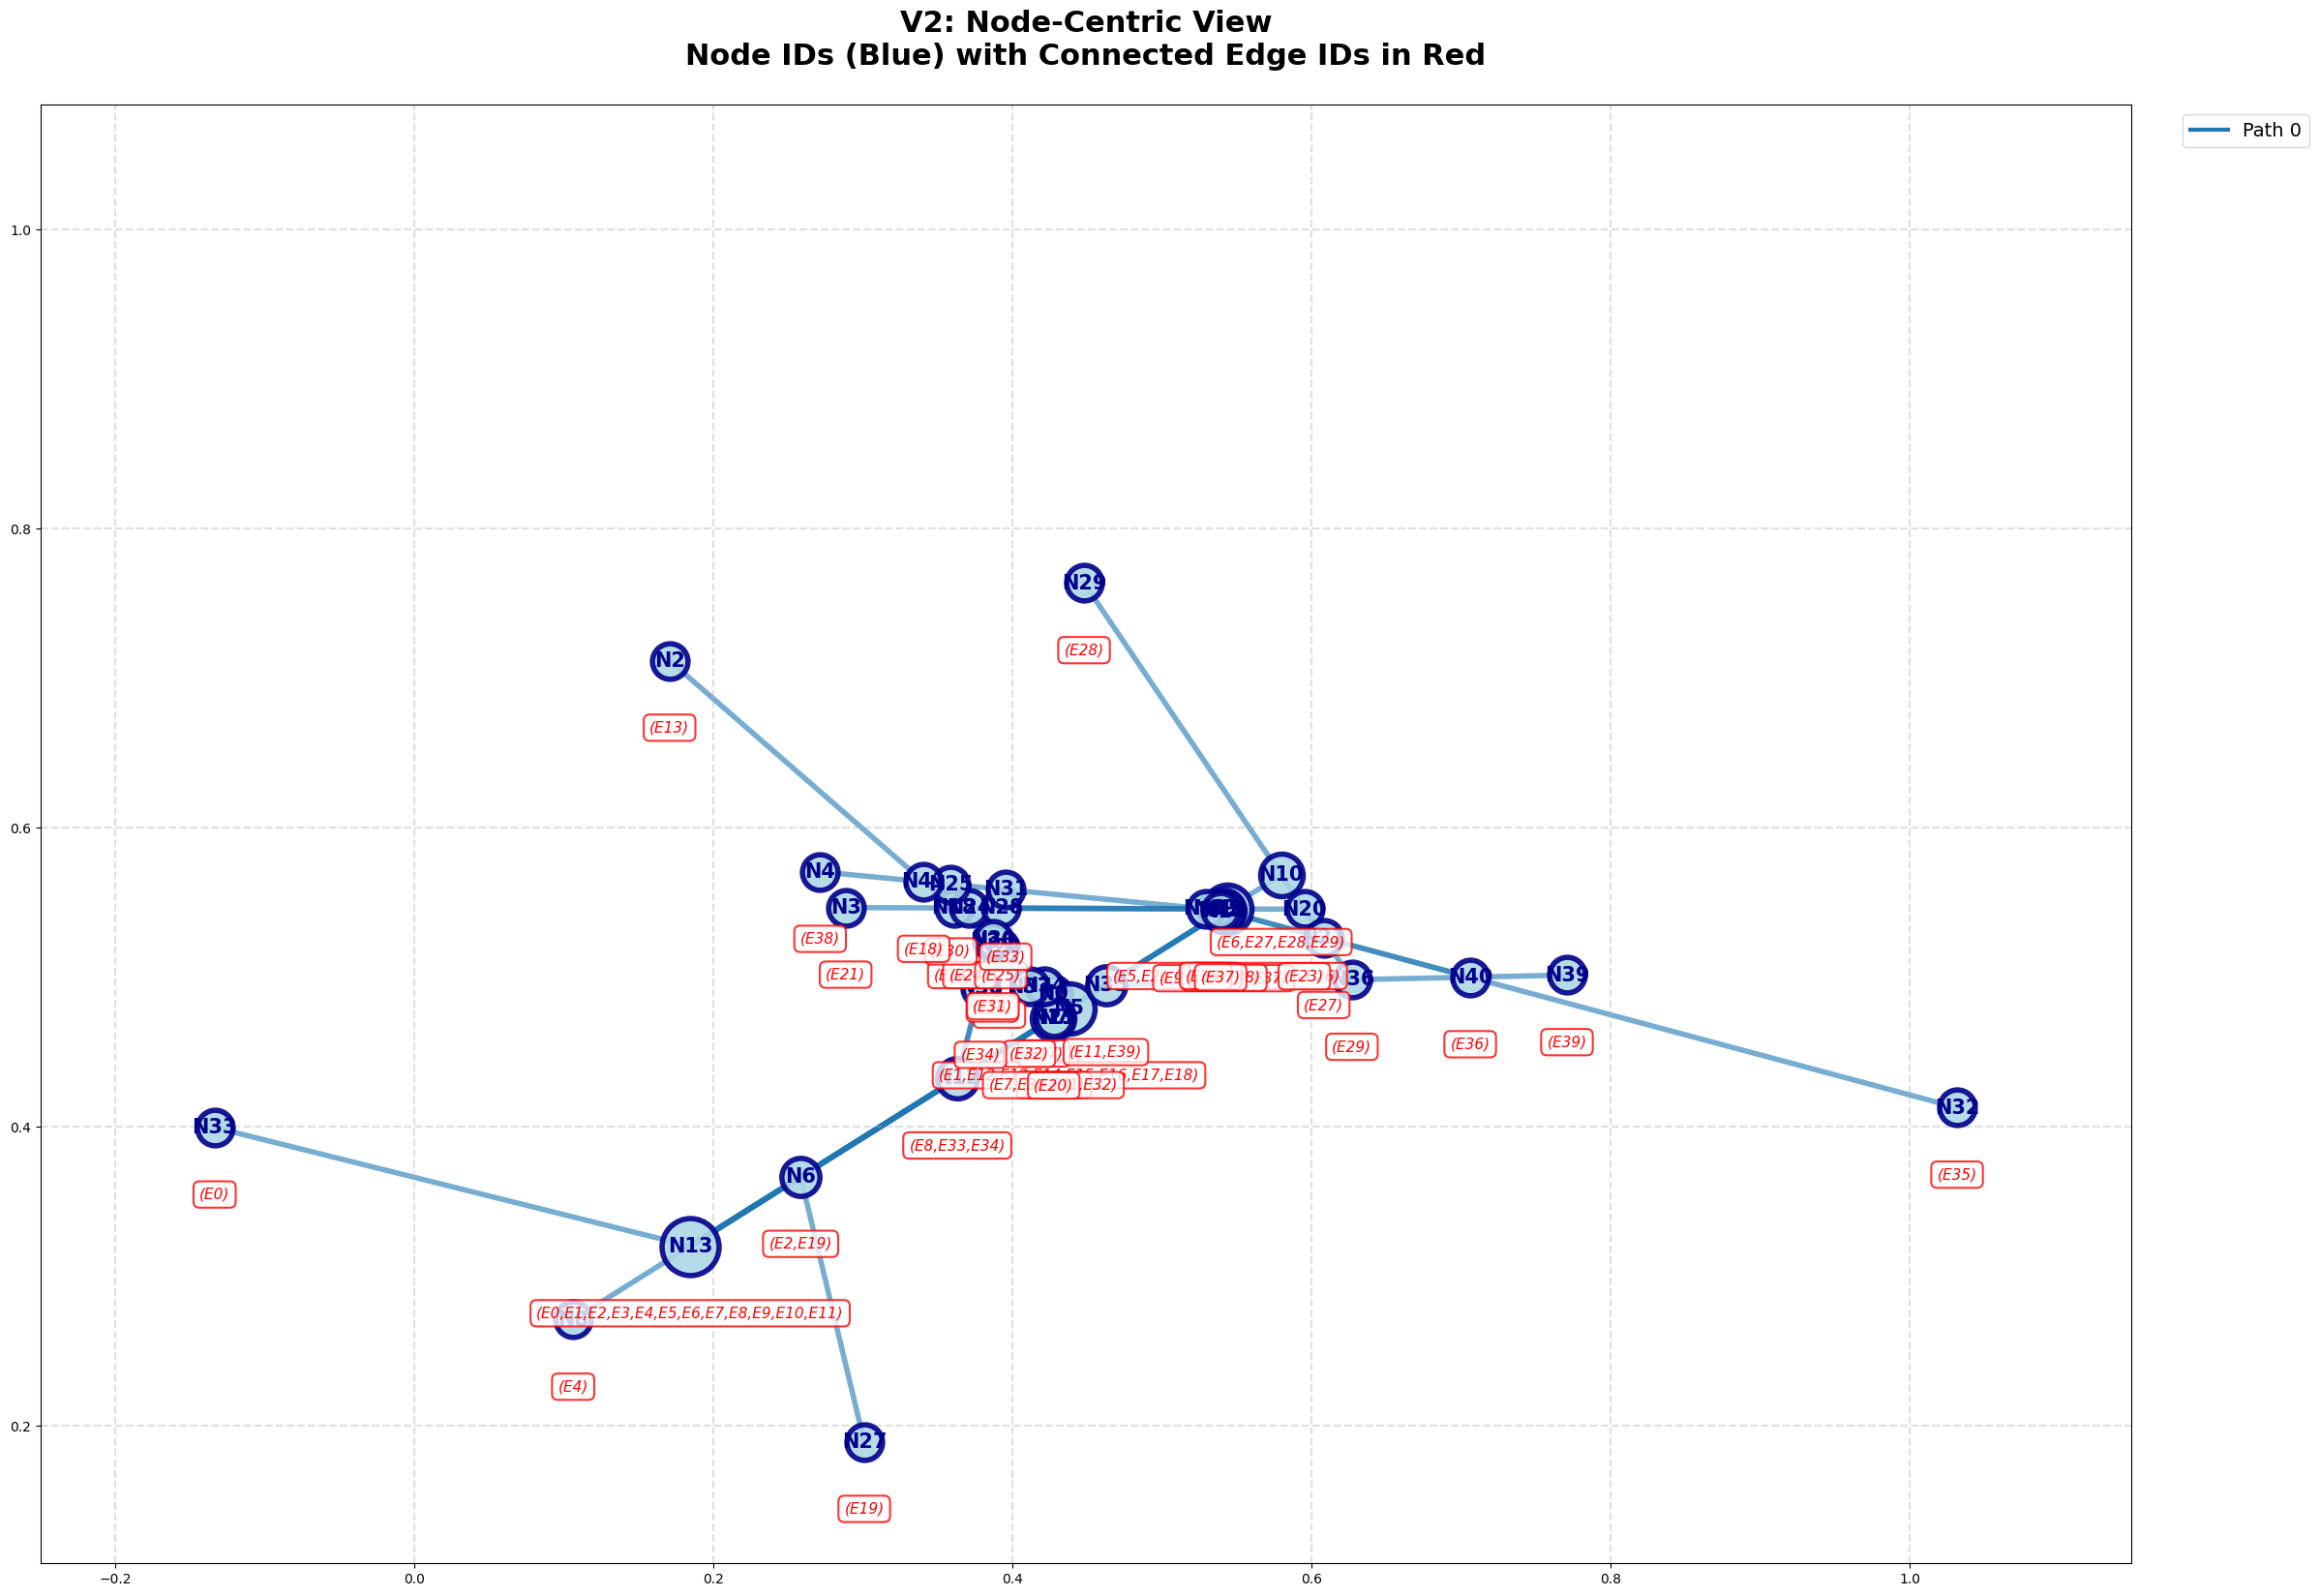


V2: NODE-CENTRIC VIEW - Node Information
Node N0: degree 1, connected to edges [12]
Node N2: degree 1, connected to edges [13]
Node N3: degree 1, connected to edges [21]
Node N4: degree 1, connected to edges [38]
Node N5: degree 8, connected to edges [1, 12, 13, 14, 15, 16, 17, 18]
Node N6: degree 2, connected to edges [2, 19]
Node N7: degree 2, connected to edges [3, 20]
Node N8: degree 1, connected to edges [4]
Node N9: degree 7, connected to edges [5, 21, 22, 23, 24, 25, 26]
Node N10: degree 4, connected to edges [6, 27, 28, 29]
Node N11: degree 4, connected to edges [7, 30, 31, 32]
Node N12: degree 3, connected to edges [8, 33, 34]
Node N13: degree 12, connected to edges [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Node N14: degree 4, connected to edges [9, 35, 36, 37]
Node N15: degree 2, connected to edges [10, 38]
Node N18: degree 1, connected to edges [14]
Node N19: degree 1, connected to edges [22]
Node N20: degree 1, connected to edges [23]
Node N21: degree 1, connected to edges [2

In [110]:
# Generate V2 visualization
plot_node_centric_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                       edge_to_id, edge_to_nodes, node_to_edges)

## Combined view

Both views side by side.

In [111]:
def plot_combined_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                      edge_to_id, edge_to_nodes, node_to_edges, path_filter=None):
    """
    Combined visualization showing both V1 and V2 side by side.
    """
    colors = plt.cm.tab10(range(10))
    if len(path_nodes) > 10:
        colors = plt.cm.tab20(range(20))

    # Build edge adjacency graph - two edges are adjacent if they share a node
    edge_adjacency = {edge_pair: set() for edge_pair in edge_to_id.keys()}
    for node, connected_edges in node_to_edges.items():
        for i, edge1 in enumerate(connected_edges):
            for edge2 in connected_edges[i+1:]:
                edge_adjacency[edge1].add(edge2)
                edge_adjacency[edge2].add(edge1)

    # Graph coloring algorithm - assign colors ensuring adjacent edges get different colors
    edge_colors_assigned = {}
    color_palette = plt.cm.hsv(np.linspace(0, 0.95, min(len(edge_to_id), 20)))

    for edge_pair in sorted(edge_to_id.keys(), key=lambda e: len(edge_adjacency[e]), reverse=True):
        # Find which colors are used by adjacent edges
        used_colors = set()
        for adj_edge in edge_adjacency[edge_pair]:
            if adj_edge in edge_colors_assigned:
                used_colors.add(edge_colors_assigned[adj_edge])

        # Assign the first available color
        for color_idx in range(len(color_palette)):
            if color_idx not in used_colors:
                edge_colors_assigned[edge_pair] = color_idx
                break
        else:
            edge_colors_assigned[edge_pair] = len(used_colors)

    # Create color dictionary with actual colors
    max_color_idx = max(edge_colors_assigned.values()) + 1
    full_palette = plt.cm.hsv(np.linspace(0, 0.95, max_color_idx))
    edge_color_dict = {edge_pair: full_palette[color_idx]
                       for edge_pair, color_idx in edge_colors_assigned.items()}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(48, 20))  # Much larger combined window

    x_values, y_values = zip(*intersections_points)
    paths_to_show = range(len(path_nodes)) if path_filter is None else path_filter

    # --- Left plot: Edge-Centric (V1) ---
    # Create adjusted node positions to handle overlaps
    adjusted_x = {}
    adjusted_y = {}
    for node in range(len(intersections_points)):
        adjusted_x[node] = x_values[node]
        adjusted_y[node] = y_values[node]

    # Apply small offset to overlapping nodes
    for i, node_i in enumerate(range(len(intersections_points))):
        for node_j in range(i + 1, len(intersections_points)):
            dist = ((x_values[node_i] - x_values[node_j])**2 +
                   (y_values[node_i] - y_values[node_j])**2)**0.5
            if dist < 0.02:
                angle = node_i * 0.5
                adjusted_x[node_i] += 0.012 * math.cos(angle)
                adjusted_y[node_i] += 0.012 * math.sin(angle)
                adjusted_x[node_j] -= 0.012 * math.cos(angle)
                adjusted_y[node_j] -= 0.012 * math.sin(angle)

    drawn_edges_v1 = set()

    for path_idx in paths_to_show:
        if path_idx >= len(path_nodes):
            continue
        edges = path_pairs_of_edges[path_idx]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair

                if edge_pair in drawn_edges_v1:
                    continue
                drawn_edges_v1.add(edge_pair)

                edge_id = edge_to_id[edge_pair]

                # Get unique color for this edge
                edge_color = edge_color_dict[edge_pair]

                # Draw white outline first
                ax1.plot([adjusted_x[node1], adjusted_x[node2]],
                        [adjusted_y[node1], adjusted_y[node2]],
                        color='white', linewidth=6, alpha=0.9, zorder=0)

                ax1.plot([adjusted_x[node1], adjusted_x[node2]],
                        [adjusted_y[node1], adjusted_y[node2]],
                        color=edge_color, linewidth=4, alpha=1.0, zorder=1)

                # Calculate edge midpoint and direction
                mid_x_edge = (adjusted_x[node1] + adjusted_x[node2]) / 2
                mid_y_edge = (adjusted_y[node1] + adjusted_y[node2]) / 2

                dx = adjusted_x[node2] - adjusted_x[node1]
                dy = adjusted_y[node2] - adjusted_y[node1]
                edge_length = (dx**2 + dy**2)**0.5

                if edge_length > 0:
                    perp_x = -dy / edge_length
                    perp_y = dx / edge_length

                    # Use hash-based offset for better distribution and less overlap
                    hash_val = hash((node1, node2, edge_id))
                    offset_level = (hash_val % 7) - 3
                    perp_offset = 0.055 * offset_level

                    # Vary position along edge too
                    along_offset = 0.5 + ((hash_val // 7) % 5 - 2) * 0.08

                    label_x = adjusted_x[node1] + along_offset * (adjusted_x[node2] - adjusted_x[node1])
                    label_y = adjusted_y[node1] + along_offset * (adjusted_y[node2] - adjusted_y[node1])
                    label_x += perp_x * perp_offset
                    label_y += perp_y * perp_offset

                    # Draw arrow from edge to label
                    ax1.annotate('', xy=(label_x, label_y), xytext=(mid_x_edge, mid_y_edge),
                               arrowprops=dict(arrowstyle='->', color=edge_color,
                                             lw=2.5, alpha=0.9), zorder=2)

                    ax1.text(label_x, label_y, f'E{edge_id}',
                            fontsize=11, fontweight='bold', color='black',
                            bbox=dict(boxstyle='round,pad=0.4', facecolor=edge_color,
                                     edgecolor='black', alpha=1.0, linewidth=2.5),
                            ha='center', va='center', zorder=3)

    nodes_to_show = set()
    for path_idx in paths_to_show:
        if path_idx < len(path_nodes):
            nodes_to_show.update(path_nodes[path_idx])

    for node in nodes_to_show:
        ax1.scatter(adjusted_x[node], adjusted_y[node],
                   s=500, c='white', edgecolors='black',
                   linewidths=3, zorder=4, marker='o')
        ax1.text(adjusted_x[node], adjusted_y[node], f'{node}',
                fontsize=13, fontweight='bold', color='black',
                ha='center', va='center', zorder=5)

    ax1.set_title('V1: Edge-Centric\n(Edge IDs prominent)', fontsize=18, fontweight='bold')

    # Set dynamic axis limits based on actual data with margin
    x_min, x_max = min(x_values), max(x_values)
    y_min, y_max = min(y_values), max(y_values)
    x_margin = (x_max - x_min) * 0.1 if x_max > x_min else 0.1
    y_margin = (y_max - y_min) * 0.1 if y_max > y_min else 0.1
    ax1.set_xlim(x_min - x_margin, x_max + x_margin)
    ax1.set_ylim(y_min - y_margin, y_max + y_margin)
    ax1.set_aspect('equal')
    ax1.grid(True, alpha=0.3, linestyle='--')

    # --- Right plot: Node-Centric (V2) ---
    for path_idx in paths_to_show:
        if path_idx >= len(path_nodes):
            continue
        edges = path_pairs_of_edges[path_idx]
        color = colors[path_idx % len(colors)]

        for edge_pair in edges:
            if isinstance(edge_pair, tuple) and len(edge_pair) == 2:
                node1, node2 = edge_pair
                ax2.plot([x_values[node1], x_values[node2]],
                        [y_values[node1], y_values[node2]],
                        color=color, linewidth=2, alpha=0.5, zorder=1)

    node_degrees = {node: len(edges) for node, edges in node_to_edges.items()}

    for node in nodes_to_show:
        degree = node_degrees.get(node, 1)
        node_size = 600 + degree * 100

        ax2.scatter(x_values[node], y_values[node],
                   s=node_size, c='lightblue', edgecolors='darkblue',
                   linewidths=4, zorder=4, marker='o', alpha=0.9)
        ax2.text(x_values[node], y_values[node], f'N{node}',
                fontsize=15, fontweight='bold', color='darkblue',
                ha='center', va='center', zorder=5)

        if node in node_to_edges:
            connected_edges = node_to_edges[node]
            edge_ids_str = ",".join([f"E{edge_to_id[e]}" for e in connected_edges])
            ax2.text(x_values[node], y_values[node] - 0.04,
                    f'({edge_ids_str})',
                    fontsize=11, style='italic', color='red',
                    ha='center', va='top', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.4', facecolor='white',
                             alpha=0.8, edgecolor='red', linewidth=1.5))

    ax2.set_title('V2: Node-Centric\n(Node IDs prominent)', fontsize=18, fontweight='bold')
    ax2.set_xlim(x_min - x_margin, x_max + x_margin)
    ax2.set_ylim(y_min - y_margin, y_max + y_margin)
    ax2.set_aspect('equal')
    ax2.grid(True, alpha=0.3, linestyle='--')

    # Overall title
    fig.suptitle('Combined View: Edge-Centric vs Node-Centric Visualizations',
                fontsize=24, fontweight='bold', y=0.98)

    plt.tight_layout()
    plt.savefig('Combined_View.png', dpi=300, bbox_inches='tight')
    plt.show()

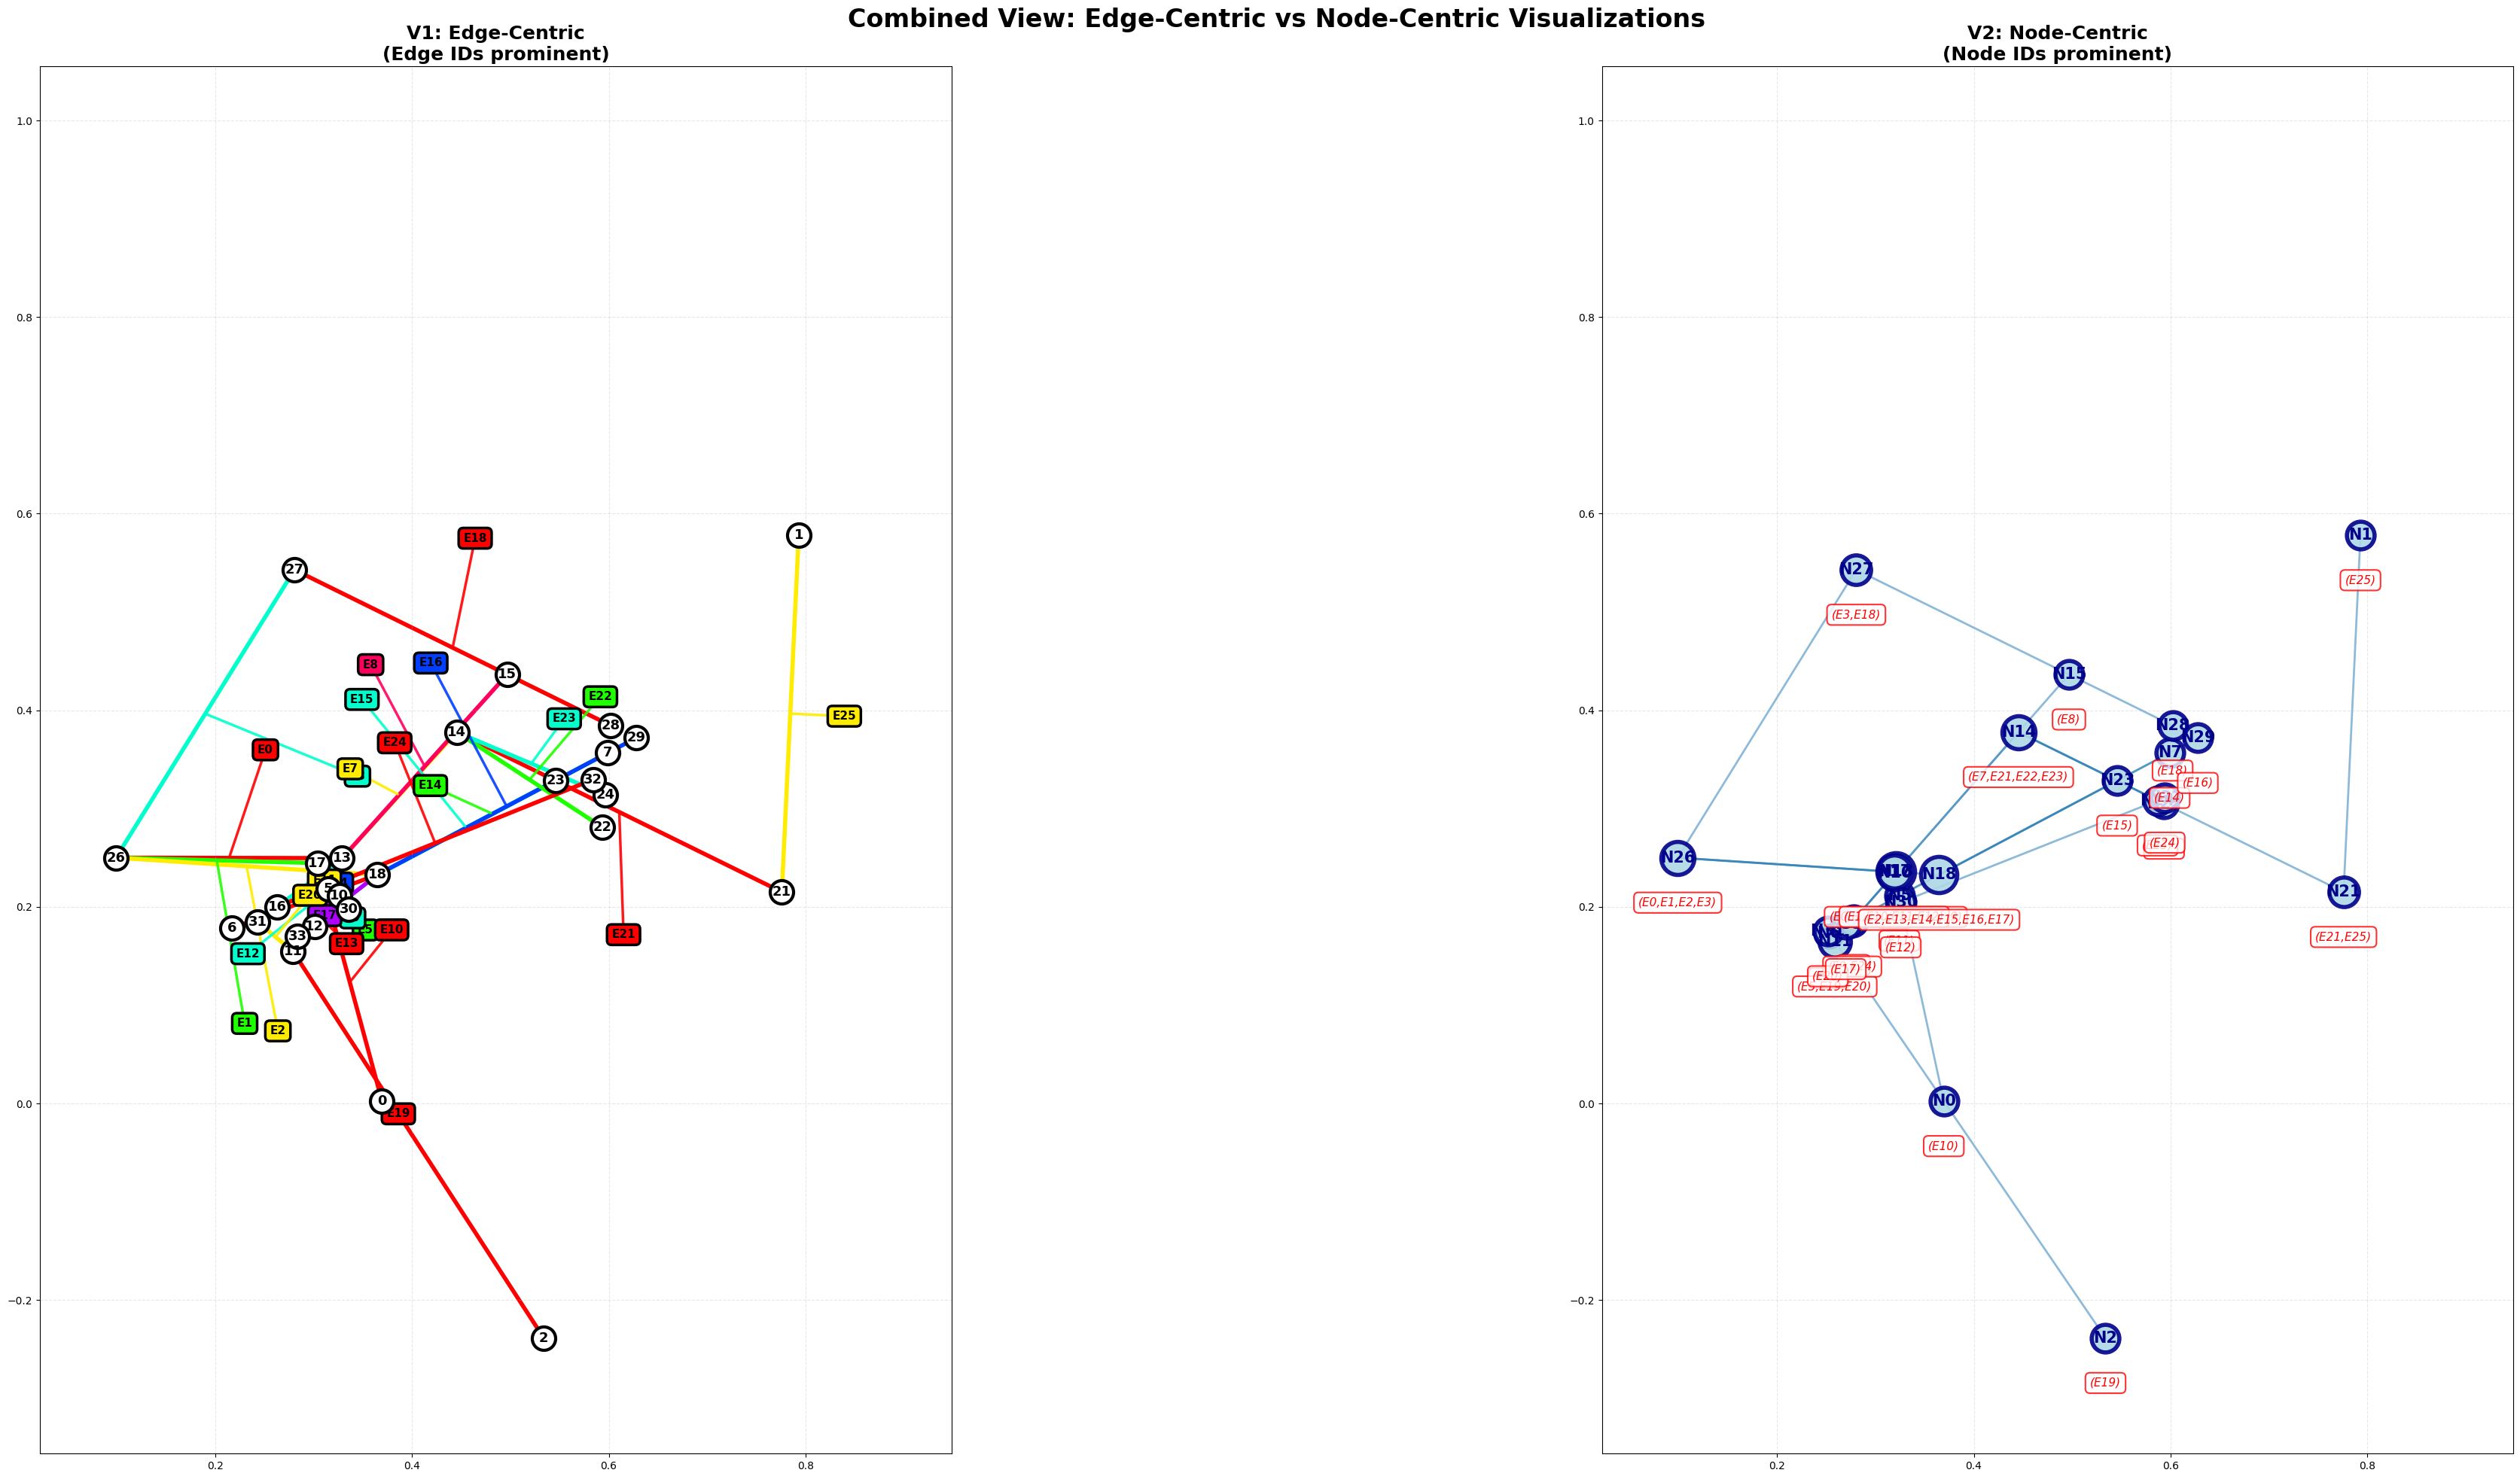

In [90]:
# Generate combined visualization
plot_combined_view(N, intersections_points, path_nodes, path_pairs_of_edges,
                   edge_to_id, edge_to_nodes, node_to_edges)